# 02 — Exploratory Data Analysis (R2)

**Project:** Birds' Species Classification · **Requirement:** R2 Data Analysis and Exploration (EDA part)

Goal: understand the cleaned data **before** modelling — what the attributes look like, how they relate to each other
and to the species, and why separating 200 species is hard. Every figure ends with a short **takeaway** used in the report.

**Input:** `data/processed/cub_attributes_clean.csv` (from `01_data_cleaning.ipynb`) and `data/processed/cub_images.csv`.

> EDA here is **descriptive** and uses the whole dataset. Anything that decides how a model is built
> (feature selection in notebook 03) uses the **training set only**, so the test set never influences modelling choices.

**Contents**
1. Setup
2. Two examples from the datasets
3. How many attributes describe each bird?
4. Attribute values within groups (colour, shape, size, bill)
5. Species × attribute profiles
6. Correlation between attributes (redundancy)
7. Which species look alike? (why 200 classes is hard)
8. PCA: how much structure is there?
9. Key findings

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

import r2_utils as u

u.set_plot_style()
df = u.load_attributes(clean=True)
images = u.load_images().set_index("image_id")
ATTR = u.attribute_columns(df)
GROUP = pd.Series({c: u.attribute_group(c) for c in ATTR})   # attribute -> its group

print(f"{len(df):,} images | {df['species'].nunique()} species | {len(ATTR)} attributes in {GROUP.nunique()} groups")

11,769 images | 200 species | 312 attributes in 28 groups


## 2. Two examples from the datasets

Each image in **Dataset 2** has a bounding box around the bird; the same image in **Dataset 1** is described by the
binary attributes that annotators marked as present.

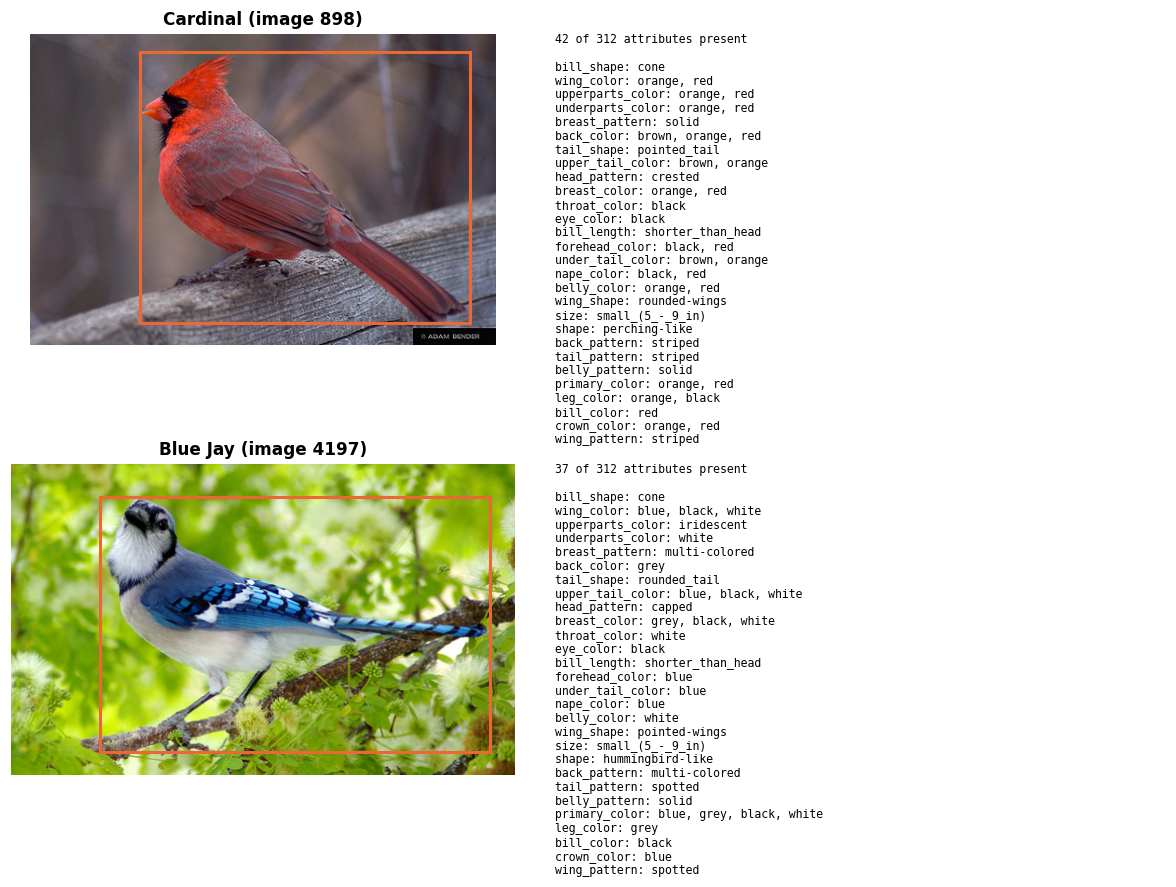

In [2]:
def show_example(ax_img, ax_txt, image_id):
    # Left: the photo with its bounding box.  Right: the attributes marked present, by group.
    meta = images.loc[image_id]
    ax_img.imshow(Image.open(u.RAW_DIR / "images" / meta["image_path"]).convert("RGB"))
    ax_img.add_patch(patches.Rectangle((meta["bbox_x"], meta["bbox_y"]), meta["bbox_w"], meta["bbox_h"],
                                       fill=False, edgecolor=u.ORANGE, linewidth=2))
    ax_img.set_title(f'{meta["species"]} (image {image_id})')
    ax_img.axis("off")

    row = df.loc[df["image_id"] == image_id, ATTR].iloc[0]
    present = [c for c in ATTR if row[c] == 1]
    lines = {}
    for c in present:
        lines.setdefault(u.attribute_group(c), []).append(u.attribute_value(c))
    text = "\n".join(f"{g}: {', '.join(v)}" for g, v in lines.items())
    ax_txt.text(0, 1, f"{len(present)} of 312 attributes present\n\n{text}", va="top", fontsize=7.5,
                family="monospace")
    ax_txt.axis("off")


def first_train_image(species):
    return int(df[(df["species"] == species) & (df["is_train"] == 1)]["image_id"].min())


fig, axes = plt.subplots(2, 2, figsize=(11, 8), gridspec_kw={"width_ratios": [1, 1.1]})
for r, species in enumerate(["Cardinal", "Blue Jay"]):
    show_example(axes[r, 0], axes[r, 1], first_train_image(species))
plt.tight_layout()
u.save_figure(fig, "02_examples")
plt.show()

**Takeaway:** each bird is described by a few dozen present attributes (colours of body parts, patterns, shape, size).
The annotations are useful but **noisy**: this Blue Jay is labelled with a *hummingbird-like* shape and the Cardinal with
a *brown* back. The box shows the bird often fills only part of the photo.

## 3. How many attributes describe each bird?

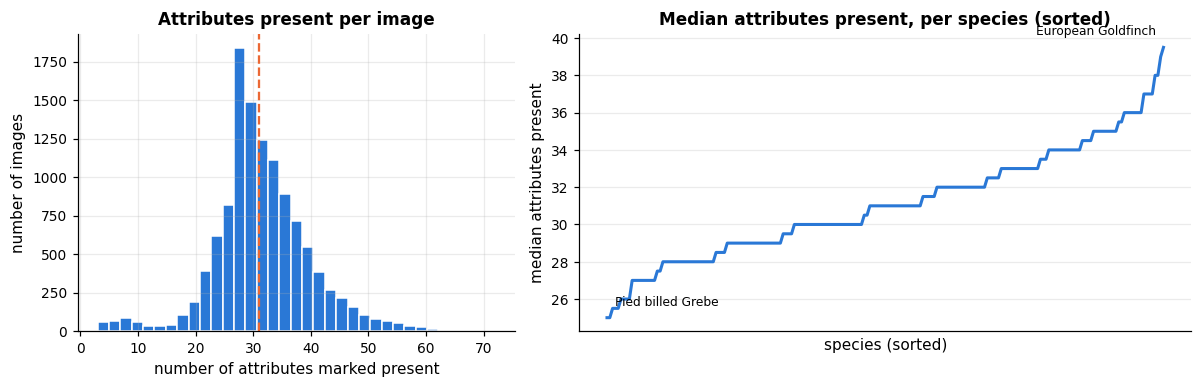

,count,mean,std,min,25%,50%,75%,max
n_present,11769.0,31.5,8.5,3.0,27.0,31.0,36.0,72.0


In [3]:
df["n_present"] = df[ATTR].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].hist(df["n_present"], bins=35, color=u.BLUE, edgecolor="white")
axes[0].axvline(df["n_present"].median(), color=u.ORANGE, ls="--")
axes[0].set(title="Attributes present per image", xlabel="number of attributes marked present",
            ylabel="number of images")

# Spread across species: median per species, sorted
per_species = df.groupby("species")["n_present"].median().sort_values()
axes[1].plot(np.arange(len(per_species)), per_species.values, color=u.BLUE, lw=2)
for i in [0, len(per_species) - 1]:
    axes[1].annotate(per_species.index[i], (i, per_species.iloc[i]), fontsize=8,
                     xytext=(5 if i == 0 else -5, 8), textcoords="offset points",
                     ha="left" if i == 0 else "right")
axes[1].set(title="Median attributes present, per species (sorted)", xlabel="species (sorted)",
            ylabel="median attributes present", xticks=[])
plt.tight_layout()
u.save_figure(fig, "02_attributes_per_image")
plt.show()

df["n_present"].describe().round(1).to_frame().T

**Takeaway:** an image has about 31 attributes present on average (only ~10% of the 312), so the data is **sparse**.
Colourful, patterned species get many more attributes than plain ones, so similarity measures that count shared
1s will treat plain birds as "close" to each other.

## 4. Attribute values within groups

The 312 attributes come from 28 groups such as `primary_color` (15 colours) or `shape` (14 shapes).
Here we look at four groups that describe the whole bird.

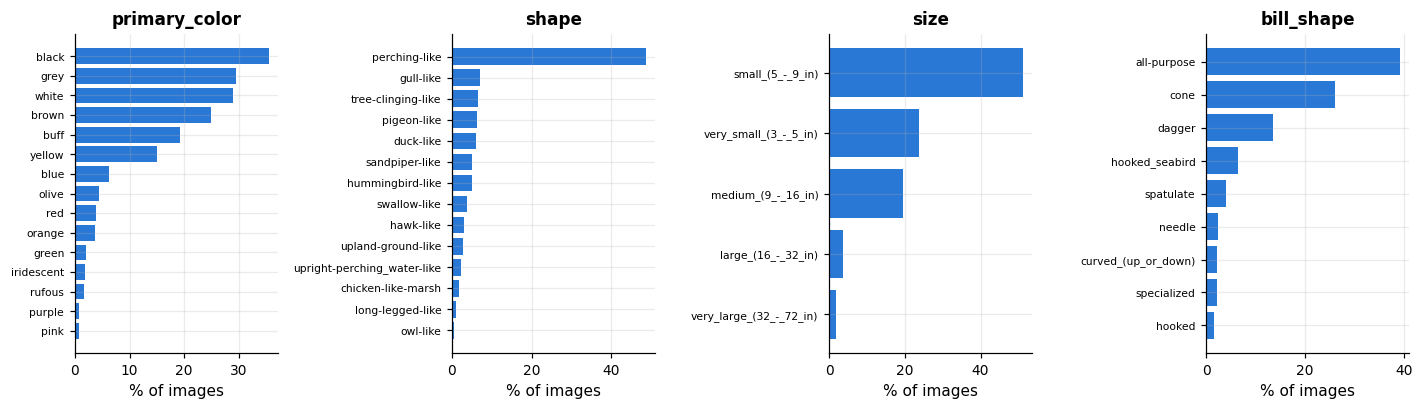

In [4]:
show_groups = ["primary_color", "shape", "size", "bill_shape"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, g in zip(axes, show_groups):
    cols = GROUP[GROUP == g].index
    share = (df[cols].mean() * 100).sort_values()
    ax.barh([u.attribute_value(c) for c in share.index], share.values, color=u.BLUE)
    ax.set(title=g, xlabel="% of images")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
u.save_figure(fig, "02_group_values")
plt.show()

**Takeaway:** most birds are small, perching-like, with black/white/grey/brown plumage and a cone or all-purpose bill —
the dataset is dominated by songbirds. Rare values (e.g. green, purple, needle bill) are typical of a few species only.

## 5. Species × attribute profiles

For each species we compute the share of its images that have each attribute (its **profile**).
Below: four species from the two largest name groups (warblers and sparrows) and four seabirds, on the
attributes that vary most between these species.

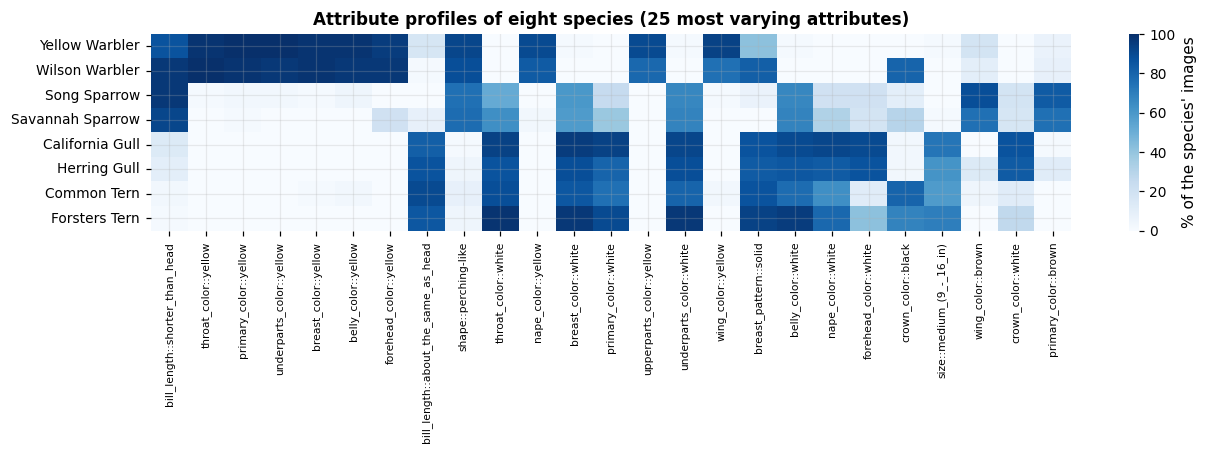

In [5]:
profiles = df.groupby("species")[ATTR].mean()

chosen = ["Yellow Warbler", "Wilson Warbler", "Song Sparrow", "Savannah Sparrow",
          "California Gull", "Herring Gull", "Common Tern", "Forsters Tern"]
sub = profiles.loc[chosen]
top_attrs = sub.var().sort_values(ascending=False).index[:25]

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(sub[top_attrs] * 100, cmap=u.SEQ_CMAP, vmin=0, vmax=100, ax=ax,
            cbar_kws={"label": "% of the species' images"},
            xticklabels=[c.replace("has_", "") for c in top_attrs])
ax.set(title="Attribute profiles of eight species (25 most varying attributes)", xlabel="", ylabel="")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
u.save_figure(fig, "02_species_profiles")
plt.show()

**Takeaway:** different *kinds* of bird (warbler vs. gull) have clearly different profiles, but species of the same kind
(California vs. Herring Gull, Common vs. Forster's Tern) have **near-identical profiles**. Also, no attribute is present
in 100% of a species' images: annotations are noisy, so each species is a "cloud" of vectors rather than one fixed vector.

## 6. Correlation between attributes

All attributes are binary, so we use the **phi coefficient** — which is exactly Pearson's *r* computed on 0/1 data
(Lecture 4: choose the association measure that matches the data types). Strong correlations mean **redundant**
attributes: they carry the same information.

In [6]:
corr = df[ATTR].corr()      # Pearson on 0/1 columns = phi coefficient

# Strongest pairs (each pair once)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("phi").reset_index()
pairs.columns = ["attribute A", "attribute B", "phi"]
pairs["same group?"] = pairs["attribute A"].map(GROUP).values == pairs["attribute B"].map(GROUP).values

print(f"Pairs with |phi| > 0.5: {(pairs['phi'].abs() > 0.5).sum()} of {len(pairs):,}")
pairs.reindex(pairs["phi"].abs().sort_values(ascending=False).index).head(12).round(3)

Pairs with |phi| > 0.5: 400 of 48,516


,attribute A,attribute B,phi,same group?
13162,has_underparts_color::yellow,has_belly_color::yellow,0.907,False
14743,has_underparts_color::white,has_belly_color::white,0.881,False
13070,has_underparts_color::yellow,has_breast_color::yellow,0.856,False
35936,has_forehead_color::blue,has_crown_color::blue,0.854,False
13428,has_underparts_color::olive,has_belly_color::olive,0.846,False
28507,has_breast_color::yellow,has_belly_color::yellow,0.840,False
15003,has_underparts_color::red,has_belly_color::red,0.837,False
35314,has_bill_length::about_the_same_as_head,has_bill_length::shorter_than_head,-0.825,True
36095,has_forehead_color::brown,has_crown_color::brown,0.825,False
2777,has_wing_color::blue,has_upperparts_color::blue,0.824,False


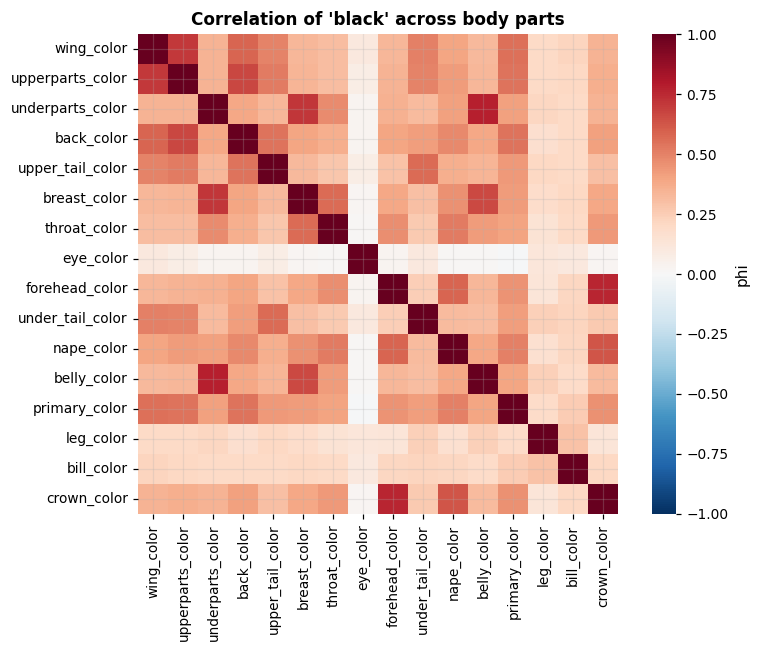

In [7]:
# Example of redundancy: the colour 'black' recorded separately for 14 body parts
black_cols = [c for c in ATTR if c.endswith("::black")]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr.loc[black_cols, black_cols], cmap=u.DIV_CMAP, vmin=-1, vmax=1, ax=ax, square=True,
            xticklabels=[u.attribute_group(c) for c in black_cols],
            yticklabels=[u.attribute_group(c) for c in black_cols], cbar_kws={"label": "phi"})
ax.set_title("Correlation of 'black' across body parts")
plt.tight_layout()
u.save_figure(fig, "02_black_correlation")
plt.show()

**Takeaway:** the strongest correlations are the **same colour on neighbouring body parts** (e.g. upperparts/back/wing,
belly/breast/underparts). These features are partly redundant, which motivates feature selection with a redundancy check
(notebook 03) and means models such as Naïve Bayes, which assume independent features, will "double count" evidence.

## 7. Which species look alike?

We compare species profiles with **cosine similarity** (1 = identical profile). The most similar pairs are the ones
any classifier will struggle with.

In [8]:
from sklearn.metrics.pairwise import cosine_similarity

sim = pd.DataFrame(cosine_similarity(profiles), index=profiles.index, columns=profiles.index)
iu = np.triu_indices(len(sim), k=1)
similar = pd.DataFrame({"species A": sim.index[iu[0]], "species B": sim.columns[iu[1]],
                        "cosine similarity": sim.values[iu]})
similar = similar.sort_values("cosine similarity", ascending=False).reset_index(drop=True)

# Nearest other species for every species
nearest = sim.where(~np.eye(len(sim), dtype=bool)).max()
print(f"Species whose closest neighbour has similarity > 0.95: {(nearest > 0.95).sum()} of 200")
similar.head(12).round(3)

Species whose closest neighbour has similarity > 0.95: 48 of 200


,species A,species B,cosine similarity
0,American Crow,Fish Crow,0.994
1,American Crow,Common Raven,0.990
2,Common Raven,Fish Crow,0.987
3,Great Grey Shrike,Loggerhead Shrike,0.976
4,Brewer Blackbird,Shiny Cowbird,0.974
5,California Gull,Herring Gull,0.972
6,Blue Grosbeak,Indigo Bunting,0.971
7,Common Tern,Forsters Tern,0.970
8,Groove billed Ani,Shiny Cowbird,0.969
9,Caspian Tern,Elegant Tern,0.968


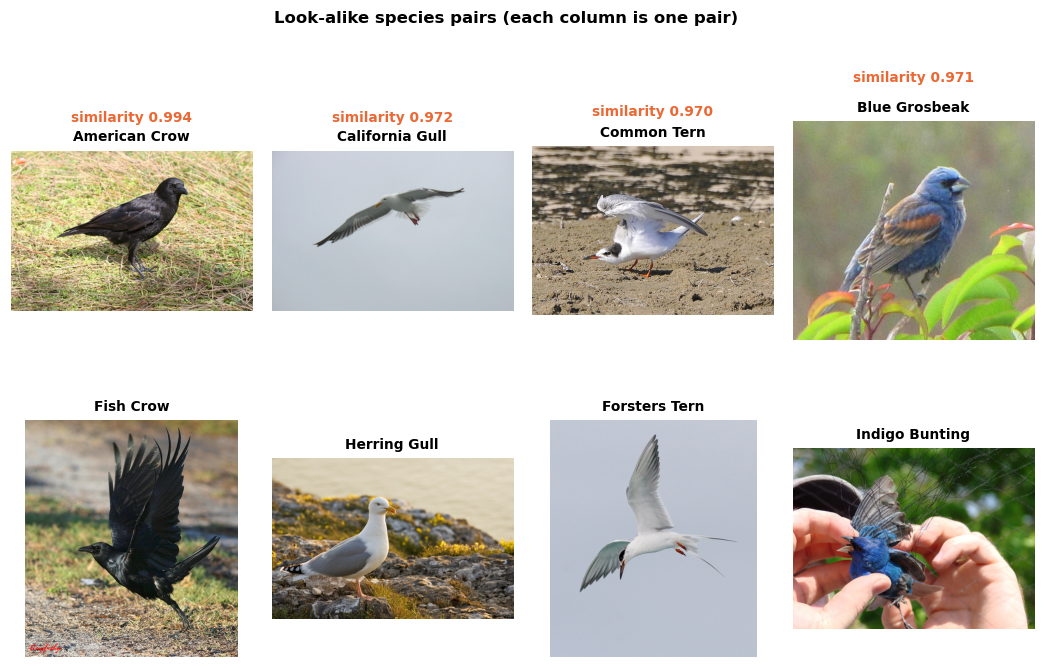

In [9]:
look_alikes = [("American Crow", "Fish Crow"), ("California Gull", "Herring Gull"),
               ("Common Tern", "Forsters Tern"), ("Blue Grosbeak", "Indigo Bunting")]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.6))
for col, pair in enumerate(look_alikes):
    for row, species in enumerate(pair):
        meta = images.loc[first_train_image(species)]
        axes[row, col].imshow(Image.open(u.RAW_DIR / "images" / meta["image_path"]).convert("RGB"))
        axes[row, col].set_title(species, fontsize=9)
        axes[row, col].axis("off")
    s = sim.loc[pair[0], pair[1]]
    axes[0, col].text(0.5, 1.18, f"similarity {s:.3f}", transform=axes[0, col].transAxes,
                      ha="center", fontsize=9, color=u.ORANGE, fontweight="bold")
fig.suptitle("Look-alike species pairs (each column is one pair)", fontweight="bold", y=1.0)
fig.subplots_adjust(hspace=0.3, wspace=0.08, top=0.86)
u.save_figure(fig, "02_look_alikes")
plt.show()

**Takeaway:** many species have a near-identical neighbour (crows/raven, gulls, terns, blue finches). This is the core
difficulty of **fine-grained** classification, and the reason accuracy on 200 species will be far below 100% even
though every model beats chance (0.5%) by a wide margin. Confusions between these pairs should be analysed in R3/R4.

## 8. PCA: how much structure is there?

Principal Component Analysis (Lecture 8) finds the directions of largest variance. We use it to (a) see how many
dimensions really carry information and (b) get a 2-D picture of the data.

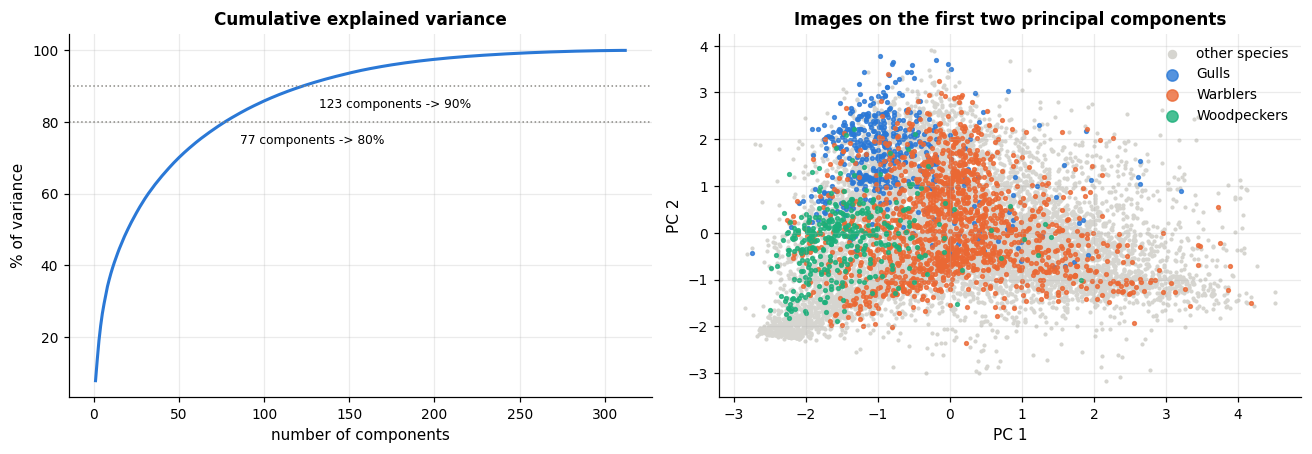

PC1 + PC2 explain 13.6% of the variance; 80% needs 77 components, 90% needs 123.


In [10]:
from sklearn.decomposition import PCA

X = df[ATTR].values
pca = PCA(random_state=u.RANDOM_STATE).fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
n80, n90 = np.searchsorted(cum, 0.80) + 1, np.searchsorted(cum, 0.90) + 1

Z = pca.transform(X)[:, :2]
highlight = {"Gull": u.BLUE, "Warbler": u.ORANGE, "Woodpecker": u.AQUA}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(np.arange(1, len(cum) + 1), cum * 100, color=u.BLUE, lw=2)
for n, level in [(n80, 80), (n90, 90)]:
    axes[0].axhline(level, color=u.GREY, ls=":", lw=1)
    axes[0].annotate(f"{n} components -> {level}%", (n, level), xytext=(10, -14),
                     textcoords="offset points", fontsize=8)
axes[0].set(title="Cumulative explained variance", xlabel="number of components", ylabel="% of variance")

others = ~df["name_group"].isin(highlight)
axes[1].scatter(Z[others, 0], Z[others, 1], s=3, color="#d6d5d0", label="other species")
for group, colour in highlight.items():
    m = (df["name_group"] == group).values
    axes[1].scatter(Z[m, 0], Z[m, 1], s=6, color=colour, label=f"{group}s", alpha=0.8)
axes[1].set(title="Images on the first two principal components", xlabel="PC 1", ylabel="PC 2")
axes[1].legend(markerscale=3, loc="upper right")
plt.tight_layout()
u.save_figure(fig, "02_pca")
plt.show()

print(f"PC1 + PC2 explain {cum[1]:.1%} of the variance; 80% needs {n80} components, 90% needs {n90}.")

In [11]:
# What do the first two components mean? Attributes with the largest weights.
loadings = pd.DataFrame(pca.components_[:2].T, index=ATTR, columns=["PC1", "PC2"])
top = {pc: loadings[pc].sort_values(key=abs, ascending=False).head(6) for pc in ["PC1", "PC2"]}
pd.DataFrame({f"{pc} attribute": s.index for pc, s in top.items()} |
             {f"{pc} weight": s.values.round(3) for pc, s in top.items()})[
    ["PC1 attribute", "PC1 weight", "PC2 attribute", "PC2 weight"]]

,PC1 attribute,PC1 weight,PC2 attribute,PC2 weight
0,has_wing_color::brown,0.215,has_wing_color::grey,0.260
1,has_primary_color::brown,0.205,has_primary_color::grey,0.258
2,has_upperparts_color::brown,0.202,has_upperparts_color::grey,0.256
3,has_primary_color::black,-0.196,has_back_color::grey,0.229
4,has_wing_color::black,-0.179,has_nape_color::grey,0.199
5,has_back_color::brown,0.176,has_crown_color::grey,0.184


**Takeaway:** variance is spread over many directions (the first two components explain only ~14%; 80% of the variance
needs 77 components and 90% needs 123), so the data has **no simple low-dimensional structure**. The first component contrasts **brown vs. black**
plumage and the second captures **grey** plumage (which is why gulls sit high on PC2). Broad kinds of bird form visible
regions (gulls separate from warblers along the first components), while species *within* a kind overlap — consistent
with Section 7.

## 9. Key findings (for the report)

1. **Sparse binary data:** ~31 of 312 attributes present per image; prevalence is highly skewed (notebook 01).
2. **Noisy labels:** no attribute is present in all images of a species — each species is a cloud of vectors.
3. **Redundancy:** the same colour on neighbouring body parts is strongly correlated → feature selection should
   consider redundancy, and Naïve Bayes' independence assumption is violated.
4. **Fine-grained difficulty:** many species have a near-identical profile (cosine > 0.95 to their closest neighbour),
   e.g. crows/raven, gulls, terns. Expect confusion between these pairs.
5. **No low-dimensional shortcut:** PCA needs 77 components for 80% of the variance; broad bird types separate,
   species within a type do not.
6. **Images:** the bird typically covers about a third of the photo (notebook 01), supporting bounding-box cropping for R4.